# Lecture 7 — Class Exercise
## Part-to-Whole: Hierarchical Visualization

> **Push to:** `week07/lecture07_exercise.ipynb`


In [3]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Global Energy Mix by Country and Source
df = pd.read_csv('global_energy_mix.csv')

# Source type mapping — reuse from lecture
source_category = {
    'Coal': 'Fossil', 'Oil': 'Fossil', 'Natural Gas': 'Fossil',
    'Nuclear': 'Low-carbon', 'Hydro': 'Low-carbon',
    'Wind': 'Renewable', 'Solar': 'Renewable', 'Other Renewables': 'Renewable'
}
df['Source_Type'] = df['Source'].map(source_category)

print(f"Loaded: {len(df)} rows")
print(df.head(10))


Loaded: 103 rows
         Country         Region            Source  Share_pct     TWh  \
0  United States  North America              Coal         10  1015.0   
1  United States  North America               Oil         35  3220.0   
2  United States  North America       Natural Gas         34  3083.0   
3  United States  North America           Nuclear          9   798.0   
4  United States  North America             Hydro          3   339.0   
5  United States  North America              Wind          4   413.0   
6  United States  North America             Solar          3   325.0   
7  United States  North America  Other Renewables          2   229.0   
8          China           Asia              Coal         58  6929.1   
9          China           Asia               Oil         18  1620.0   

  Source_Type  
0      Fossil  
1      Fossil  
2      Fossil  
3  Low-carbon  
4  Low-carbon  
5   Renewable  
6   Renewable  
7   Renewable  
8      Fossil  
9      Fossil  


## Task 1 — Treemap: fossil fuel dependency by country

**What to build:** A treemap showing **fossil fuel TWh only**, broken down by Region → Country → Source (Coal / Oil / Natural Gas).

**Requirements:**
- Filter to fossil sources only before plotting
- Use `path=['Region', 'Country', 'Source']` for the hierarchy
- Colour encodes the fossil source type (Coal / Oil / Natural Gas) with a CVD-safe palette
- Show TWh values in labels — no percentages
- Grey out parent nodes (Region and Country level)
- Insight title naming which region or country is most fossil-dependent

> 💡 `df.loc[df['Source_Type'] == 'Fossil']`


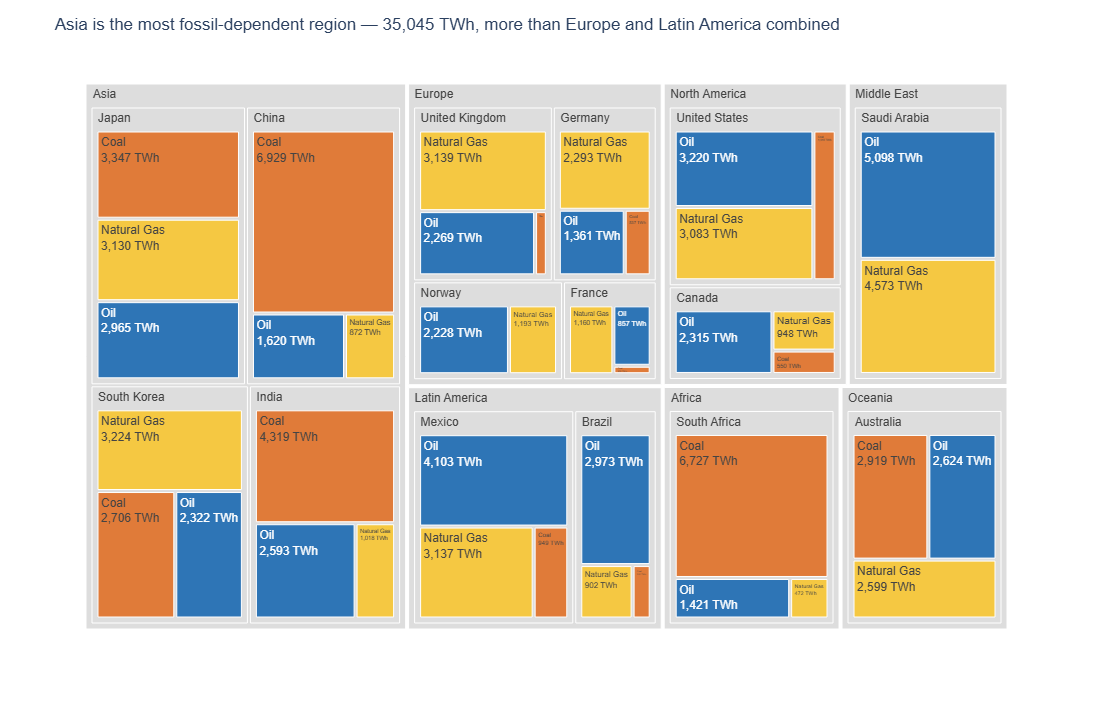

In [5]:
# Task 1
df_fossil = df.loc[df['Source_Type'] == 'Fossil'].copy()

fossil_mapping = {
    'Coal':        '#E07B39',   
    'Oil':         '#2E75B6',  
    'Natural Gas': '#F5C842',  
}

fig = px.treemap(
    df_fossil,
    path=['Region', 'Country', 'Source'],
    values='TWh',
    color='Source',
    color_discrete_map=fossil_mapping,
    labels={'Source': 'Fossil source', 'TWh': 'Energy (TWh)'},
    height=700, width=1100,
    template='plotly_white'
)

fig.update_traces(
    texttemplate='%{label}<br>%{value:,.0f} TWh',         
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} TWh<extra></extra>',
)

fig.update_layout(
    title='Asia is the most fossil-dependent region — 35,045 TWh, more than Europe and Latin America combined',
    font=dict(family='Arial', size=12),
)
fig.data[0].marker.colors = [
    c if c in fossil_mapping.values() else '#DDDDDD'
    for c in fig.data[0].marker.colors
]

fig.show()


## Task 2 — Treemap vs bar: low-carbon energy by country

**What to build:** Build **both** a treemap and a horizontal bar chart showing total low-carbon TWh (Nuclear + Hydro) per country. Then answer the question in a markdown cell below.

**Requirements:**
- Filter to `Source_Type == 'Low-carbon'` and aggregate TWh by country
- Treemap: single-level `path=['All', 'Country']` with a dummy root node labelled `'Low-carbon'`
- Bar chart: sorted by TWh, horizontal orientation, CVD-safe colour
- Both charts show TWh values, not percentages
- Insight title on the bar chart naming the leading country

In [ ]:
# Task 2 — charts

df_low = df.loc[df['Source_Type'] == 'Low-carbon'].groupby('Country')['TWh'].sum().reset_index()
df_low['All'] = 'Low-carbon'     

fig = px.treemap(
    df_low,
    path=['All', 'Country'],
    values='TWh',
    color='All',
    color_discrete_map={'Low-carbon': '#2E75B6'},  
    height=600, width=1000,
    template='plotly_white'
)

fig.update_traces(
    texttemplate='%{label}<br>%{value:,.0f} TWh',
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} TWh<extra></extra>',
)

fig.update_layout(
    title='Low-carbon energy (Nuclear + Hydro) by country',
    font=dict(family='Arial', size=12),
)

fig.show()


fig = px.bar(
    df_low.sort_values('TWh'),         
    x='TWh', y='Country',
    orientation='h',
    text='TWh',
    color_discrete_sequence=['#2E75B6'],
    labels={'TWh': 'Low-carbon energy (TWh)', 'Country': ''},
    height=600, width=1000,
    template='plotly_white'
)

fig.update_traces(texttemplate='%{x:,.0f} TWh', textposition='outside')

fig.update_layout(
    title='France leads low-carbon energy with 7,593 TWh — almost all of it nuclear',
    font=dict(family='Arial', size=12),
    xaxis=dict(showgrid=False),
)

fig.show()

### Task 2 — reflection

**Which chart tells the ranking story more clearly, and why?**

The bar chart. The bars all start from the same line and are sorted by TWh, so you can see the order right away: France first, then Norway, Canada and Brazil. With the treemap you have to compare the size of rectangles, and that's hard, especially when two countries have similar values. A treemap also can't be sorted from top to bottom, so the ranking isn't obvious.

## Task 3 — 100% stacked bar: which region relies most on coal?

**What to build:** A horizontal 100% stacked bar chart showing, for each **Region**, how its fossil energy splits between Coal, Oil and Natural Gas. This is the **same data as your Task 1 treemap**, visualised a second way.

**Requirements:**
- Reuse `df_fossil` from Task 1; aggregate TWh by `Region` × `Source` and convert to **shares of each region's fossil total**
- Horizontal bars, regions **sorted by coal share** (highest at the top)
- Coal is the segment on the baseline (first in `category_orders`) and the **only coloured segment** — keep it the same colour as in Task 1; Oil and Natural Gas in two greys
- Percentage labels on the coal segments only
- Insight title naming the most coal-dependent region and its coal share

> 💡 `df.groupby('Region')['TWh'].transform('sum')` gives each row its region total

In [ ]:
# Task 3

fossil_mix = df_fossil.groupby(['Region', 'Source'])['TWh'].sum().reset_index()
fossil_mix['Share'] = fossil_mix['TWh'] / fossil_mix.groupby('Region')['TWh'].transform('sum')   

region_order = (fossil_mix.pivot_table(index='Region', columns='Source', values='Share', fill_value=0)['Coal']
                          .sort_values(ascending=False).index.tolist())

fossil_mix['Label'] = np.where(fossil_mix['Source'] == 'Coal', fossil_mix['Share'].map('{:.0%}'.format), '')

accent_mapping = {
    'Coal':        '#E07B39',   
    'Oil':         '#BBBBBB',   
    'Natural Gas': '#DDDDDD',  
}

fig = px.bar(
    data_frame=fossil_mix,
    x='Share', y='Region',
    color='Source',
    text='Label',
    color_discrete_map=accent_mapping,
    category_orders={'Region': region_order,
                     'Source': ['Coal', 'Oil', 'Natural Gas']},  
    labels={'Share': 'Share of fossil energy', 'Source': 'Fossil source'},
    hover_name='Region',
    hover_data={'Label': False, 'Share': ':.2f'},
    height=600, width=1000,
    template='plotly_white',
)

fig.update_traces(
    textposition='inside', insidetextanchor='start',
    textfont=dict(color='white', size=11),
    marker_line_color='white', marker_line_width=1,
)

fig.update_layout(
    title=dict(text='Africa is the most coal-dependent region — 78% of its fossil energy comes from coal'),
    font=dict(family='Arial', size=12),
    bargap=0.25,
    legend=dict(orientation='h', x=0, y=1.04),
    xaxis=dict(visible=False, range=[0, 1]),
    yaxis=dict(title=''))

fig.add_annotation(
    x=1, y=0,
    xref='x', yref='paper',
    xanchor='right', yanchor='top',
    yshift=-4,
    text='100%',
    showarrow=False,
    font=dict(size=11, color='grey'),
)

fig.show()

### Task 3 — reflection

**Your Task 1 treemap and this stacked bar show the same fossil data. Name one question each chart answers that the other cannot.**

Treemap: shows which region uses the most fossil energy in total (Asia) and which countries it comes from.

Stacked bar: shows which region depends most on coal (Africa, 78%). Every bar is 100%, so the shares are easy to compare.